# Da emissão ao produto final: rede bipartida de atribuição de CO₂

**Pergunta:** como as relações entre setores emissores e produtos destinados à demanda final organizam a redistribuição setorial das emissões entre as atribuições pela produção e pela demanda no Brasil em 2015?

**Objetivo:** construir a rede de atribuição, medir concentração e diversidade de origens e destinos e identificar as relações que compõem as diferenças entre as duas contas. O procedimento poderá ser aplicado à MIP catarinense na dissertação; os resultados nacionais não serão transferidos ao estado.

Percurso: dados → sistema econômico → intensidades → C e F → contas → rede NetworkX → diversidade → figuras e interpretação.

**Cenário exploratório, não inventário validado.** Coeficientes de Sanguinet e Azzoni interpolados de 2011/2018, sem deflação efetiva. A [auditoria ambiental](docs/auditoria_coeficientes_emissoes_2015.md) registra limitações de cobertura, preços e alocação. Todas as interpretações ambientais são condicionais. Referencial: Miller e Blair (2009), capítulos 2 e 10; entropia e seleção gráfica são escolhas operacionais deste trabalho.

Fronteira: produção nacional, incluindo exportações; exclui emissões estrangeiras e emissões diretas das famílias fora da produção setorial. Execute da raiz do repositório, usando as dependências já previstas no projeto.

## 1. Preparação e entradas
Os carregadores verificam o SHA-256 das entradas canônicas. Não dependemos de matrizes exportadas por outros notebooks.

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display
from redes import dados, mip
from redes.visualizacoes import ROTULOS_ATIVIDADES_IBGE
saida=Path('outputs/rede_bipartida_atribuicao_2015')
saida.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'font.size':10})
pd.set_option('display.max_columns',12)
tabelas=dados.carregar_matriz_67('mip_ibge_2015_67')

SHA-256 verificado: Matriz_de_Insumo_Produto_2015_Nivel_67.xls.original


## 2. Sistema econômico: produção, transações e demanda

$$x=V^T\mathbf1,\quad Z=DU,\quad y=Df,\quad A=Z\widehat x^{-1},\quad L=(I-A)^{-1}.$$

V registra produtos por atividade; U, usos intermediários nacionais; D converte produtos em atividades fornecedoras. Linhas de Z são fornecedoras e colunas são compradoras. Demanda final inclui exportações. Mantemos ajustes contábeis na reconstrução e comparamos A e L às tabelas oficiais.

In [2]:
V=mip.carregar_matriz_producao_tabela_01_67(tabelas)
U=mip.carregar_matriz_uso_nacional_tabela_03_67(tabelas)
D=mip.carregar_matriz_participacao_tabela_13_67(tabelas)
x=V.sum(axis=0)
f=pd.Series(tabelas['03'].iloc[5:132,77].to_numpy(dtype=float),index=U.index)
assert D.columns.equals(U.index) and D.columns.equals(f.index)
assert D.index.equals(x.index) and U.columns.equals(x.index)
assert (x>0).all()
Z=D@U
y=D@f
A=Z.div(x,axis=1)
L=pd.DataFrame(np.linalg.solve(np.eye(len(x))-A.to_numpy(),np.eye(len(x))),index=x.index,columns=x.index)
np.testing.assert_allclose(x,Z.sum(axis=1)+y,rtol=0,atol=1e-6)
np.testing.assert_allclose(L@y,x,rtol=0,atol=1e-6)
np.testing.assert_allclose(A,mip.carregar_coeficientes_tecnicos_67(tabelas),rtol=0,atol=1e-10)
np.testing.assert_allclose(L,mip.carregar_inversa_leontief_ibge_67(tabelas),rtol=0,atol=1e-9)
nomes=pd.Series({i:ROTULOS_ATIVIDADES_IBGE.get(str(i),str(i)) for i in x.index})
display(pd.DataFrame({'nome':nomes,'x_R_milhoes':x,'y_R_milhoes':y}).head())
print('Menores valores de Z e y:',Z.min().min(),y.min())

Menores valores de Z e y: -0.08468597921312317 492.6284321163217


,nome,x_R_milhoes,y_R_milhoes
0191,Agricultura e apoio,309301.0,166314.686749
0192,Pecuária e apoio,137018.0,41574.280991
0280,"Produção florestal, pesca e aquic.",32411.0,18067.217657
0580,Extração de carvão e não metálicos,19733.0,2441.707034
0680,Extração de petróleo e gás,171984.0,57860.876177


## 3. Extensão ambiental: C, c e F

$$\varphi=\varphi_{2011}+\frac47(\varphi_{2018}-\varphi_{2011}),\quad\Phi=\operatorname{diag}(\varphi),\quad C=\Phi L,\quad c=\Phi x,\quad F=C\widehat y.$$

C: Gg CO₂/R$ milhão de demanda final. F: Gg CO₂. Fᵢⱼ atribui emissões **ocorridas em i** à demanda final dos produtos de j, considerando encadeamentos diretos e indiretos. Não é venda direta nem transporte de CO₂. A correspondência ordenada S1…S67 com as atividades IBGE está documentada na auditoria, seção 6; alinhamento correto não valida o numerador físico.

In [3]:
coef11=dados.carregar_coeficientes_co2('sanguinet_azzoni_2011')[2011]
coef18=dados.carregar_coeficientes_co2('sanguinet_azzoni_2018')[2018]
assert coef11.index.equals(coef18.index)
assert coef11.index.tolist()==[f'S{i}' for i in range(1,68)]
phi=pd.Series((coef11+4/7*(coef18-coef11)).to_numpy(),index=x.index,name='phi')
assert np.isfinite(phi).all() and (phi>=0).all()
Phi=pd.DataFrame(np.diag(phi),index=x.index,columns=x.index)
C=Phi@L
c=phi*x
F=C.mul(y,axis=1)
u=F.sum(axis=0)
np.testing.assert_allclose(F.sum(axis=1),c,rtol=1e-10,atol=1e-7)
np.testing.assert_allclose(c.sum(),u.sum(),rtol=1e-12)
assert np.isfinite(F.to_numpy()).all()
assert (F.to_numpy()>=0).all(), 'Negativos em F: revisar antes de calcular participações.'
E=c.sum()
assert E>0
print(f'Total do cenário: {E/1000:,.3f} Mt CO₂; não é inventário validado.')

SHA-256 verificado: coeficientes_co2_sanguinet_azzoni_2011.csv
SHA-256 verificado: coeficientes_co2_sanguinet_azzoni_2018.csv
Total do cenário: 683.696 Mt CO₂; não é inventário validado.


## 4. Comparação das contas e decomposição do saldo

$$c_i=\sum_j F_{ij},\quad u_i=\sum_k F_{ki},\quad\Delta_i=100(u_i-c_i)/E.$$
$$u_i-c_i=\sum_{k\ne i}F_{ki}-\sum_{j\ne i}F_{ij}.$$

Δ é a diferença em pontos percentuais entre as participações pela demanda e produção. A diagonal cancela no saldo, mas integra ambas as contas. Mudança de atribuição não significa mudança física nas emissões.

In [4]:
diagonal=pd.Series(np.diag(F),index=x.index)
np.testing.assert_allclose(u-c,(u-diagonal)-(c-diagonal),atol=1e-7)
metricas=pd.DataFrame({'nome':nomes,'c_gg':c,'u_gg':u,'producao_pct':100*c/E,'demanda_pct':100*u/E,'delta_pp':100*(u-c)/E})
metricas['outras_origens_gg']=u-diagonal
metricas['outros_destinos_gg']=c-diagonal
np.testing.assert_allclose(metricas.delta_pp.sum(),0,atol=1e-10)
ordem=metricas.delta_pp.abs().sort_values(ascending=False).head(12).index
display(metricas.loc[ordem])

,nome,c_gg,u_gg,producao_pct,demanda_pct,delta_pp,outras_origens_gg,outros_destinos_gg
3680,"Água, esgoto e resíduos",51802.235714,21736.760343,7.576793,3.179302,-4.397492,1164.486455,31229.961826
8400,"Admin. pública, defesa e segurid.",24672.685714,54429.499919,3.608721,7.961067,4.352346,30496.069857,739.255652
3500,"Eletricidade, gás e utilidades",56620.651429,28227.112331,8.281553,4.128605,-4.152948,2923.503440,31317.042538
4180,Construção,38841.777143,59397.061924,5.681147,8.687642,3.006495,23483.757053,2928.472271
4580,Comércio,26732.815714,45395.641183,3.910044,6.639740,2.729696,28210.033908,9547.208440
5600,Alimentação,7660.320000,25793.597631,1.120428,3.772670,2.652243,19323.413440,1190.135809
1091,"Carnes, laticínios e pescado",29894.622857,44382.384108,4.372502,6.491537,2.119035,18227.957972,3740.196721
8000,Vigilância e segurança,13242.228571,171.486387,1.936859,0.025082,-1.911777,7.866250,13078.608434
5980,"TV, rádio, cinema, som e imagem",12277.131429,844.109205,1.795700,0.123463,-1.672238,142.530811,11575.553035
7380,Outros serv. profissionais e técn.,11861.142857,1145.194219,1.734856,0.167500,-1.567356,642.837477,11358.786115


## 5. Rede bipartida dirigida com NetworkX

Dois papéis: ('emissor', i) e ('produto', j), com aresta de peso Fᵢⱼ. Mantemos todos os 134 nós e todas as ligações positivas. Fᵢᵢ conecta papéis diferentes, não é laço. Forças de saída e entrada recuperam c e u; são identidades contábeis, não confirmações independentes. Não calculamos caminhos, betweenness ou nova inversa sobre F: os encadeamentos já estão incorporados.

In [5]:
G=nx.DiGraph()
for i in F.index:
    G.add_node(('emissor',i),bipartite=0,nome=nomes[i],total_gg=float(c[i]))
    G.add_node(('produto',i),bipartite=1,nome=nomes[i],total_gg=float(u[i]))
registros=[]
for i in F.index:
    for j in F.columns:
        peso=float(F.loc[i,j])
        if peso>0:
            G.add_edge(('emissor',i),('produto',j),weight=peso)
            registros.append({'emissor':i,'produto':j,'peso_gg':peso,'mesma_atividade':i==j})
arestas=pd.DataFrame(registros).sort_values(['peso_gg','emissor','produto'],ascending=[False,True,True])
assert nx.is_bipartite(G) and nx.number_of_selfloops(G)==0
np.testing.assert_allclose([G.out_degree(('emissor',i),weight='weight') for i in x.index],c)
np.testing.assert_allclose([G.in_degree(('produto',i),weight='weight') for i in x.index],u)
print(G.number_of_nodes(),'nós;',G.number_of_edges(),'ligações positivas.')

134 nós; 4357 ligações positivas.


## 6. Diversidade e concentração dos perfis completos

$$p_{ij}=F_{ij}/c_i,\quad r_{ij}=F_{ij}/u_j.$$
$$D_i^{dest}=\exp(-\sum_jp_{ij}\ln p_{ij}),\quad D_j^{orig}=\exp(-\sum_i r_{ij}\ln r_{ij}).$$

Quatro componentes igualmente ponderadas correspondem a número efetivo quatro. Zeros contribuem zero à entropia; totais nulos ficam indefinidos. Mantemos a diagonal e mostramos também a maior participação. Diversidade não mede volume, substituibilidade ou essencialidade.

In [6]:
p=F.div(c.replace(0,np.nan),axis=0)
r=F.div(u.replace(0,np.nan),axis=1)
metricas['destinos_efetivos']=np.exp(-(p*np.log(p.where(p>0))).sum(axis=1,min_count=1))
metricas['origens_efetivas']=np.exp(-(r*np.log(r.where(r>0))).sum(axis=0,min_count=1))
metricas['maior_destino_pct']=100*p.max(axis=1)
metricas['maior_origem_pct']=100*r.max(axis=0)
metricas['propria_destino_pct']=100*diagonal/c.replace(0,np.nan)
metricas['propria_origem_pct']=100*diagonal/u.replace(0,np.nan)
np.testing.assert_allclose(p.loc[c>0].sum(axis=1),1)
np.testing.assert_allclose(r.loc[:,u>0].sum(axis=0),1)
for col in ['destinos_efetivos','origens_efetivas']:
    assert metricas[col].dropna().between(1-1e-10,len(x)+1e-10).all()
assert np.isclose(np.exp(-np.sum(np.full(4,.25)*np.log(np.full(4,.25)))),4)
assert np.isclose(np.exp(-np.sum(np.array([1.])*np.log([1.]))),1)
display(metricas.loc[ordem,['nome','delta_pp','destinos_efetivos','origens_efetivas','maior_destino_pct','maior_origem_pct']])

,nome,delta_pp,destinos_efetivos,origens_efetivas,maior_destino_pct,maior_origem_pct
3680,"Água, esgoto e resíduos",-4.397492,12.320956,1.437483,39.713100,94.642778
8400,"Admin. pública, defesa e segurid.",4.352346,1.272332,10.230158,97.003749,43.971431
3500,"Eletricidade, gás e utilidades",-4.152948,13.799307,1.993851,44.689717,89.642924
4180,Construção,3.006495,1.627620,7.604814,92.460509,60.463100
4580,Comércio,2.729696,6.688993,15.095804,64.286559,37.857395
5600,Alimentação,2.652243,2.288320,10.881414,84.463628,33.336618
1091,"Carnes, laticínios e pescado",2.119035,1.926635,7.044336,87.488731,58.929746
8000,Vigilância e segurança,-1.911777,22.822400,1.396605,20.874726,95.412901
5980,"TV, rádio, cinema, som e imagem",-1.672238,29.452364,2.542006,13.871596,83.114648
7380,Outros serv. profissionais e técn.,-1.567356,29.968124,4.893230,15.934204,43.866510


## 7. Grafo das 18 maiores ligações

Seleção editorial, incluindo a diagonal; não define grupos naturais. Indicadores usam F completa. Informamos peso retido e omitido. Posições seguem o total de cada papel, sem significado de distância econômica. Área dos nós é proporcional ao total na rede completa; largura, ao peso da ligação. Mesma escala entre os dois papéis.

Peso omitido: 57.5%. Ligações entre a mesma atividade: 16 de 18.


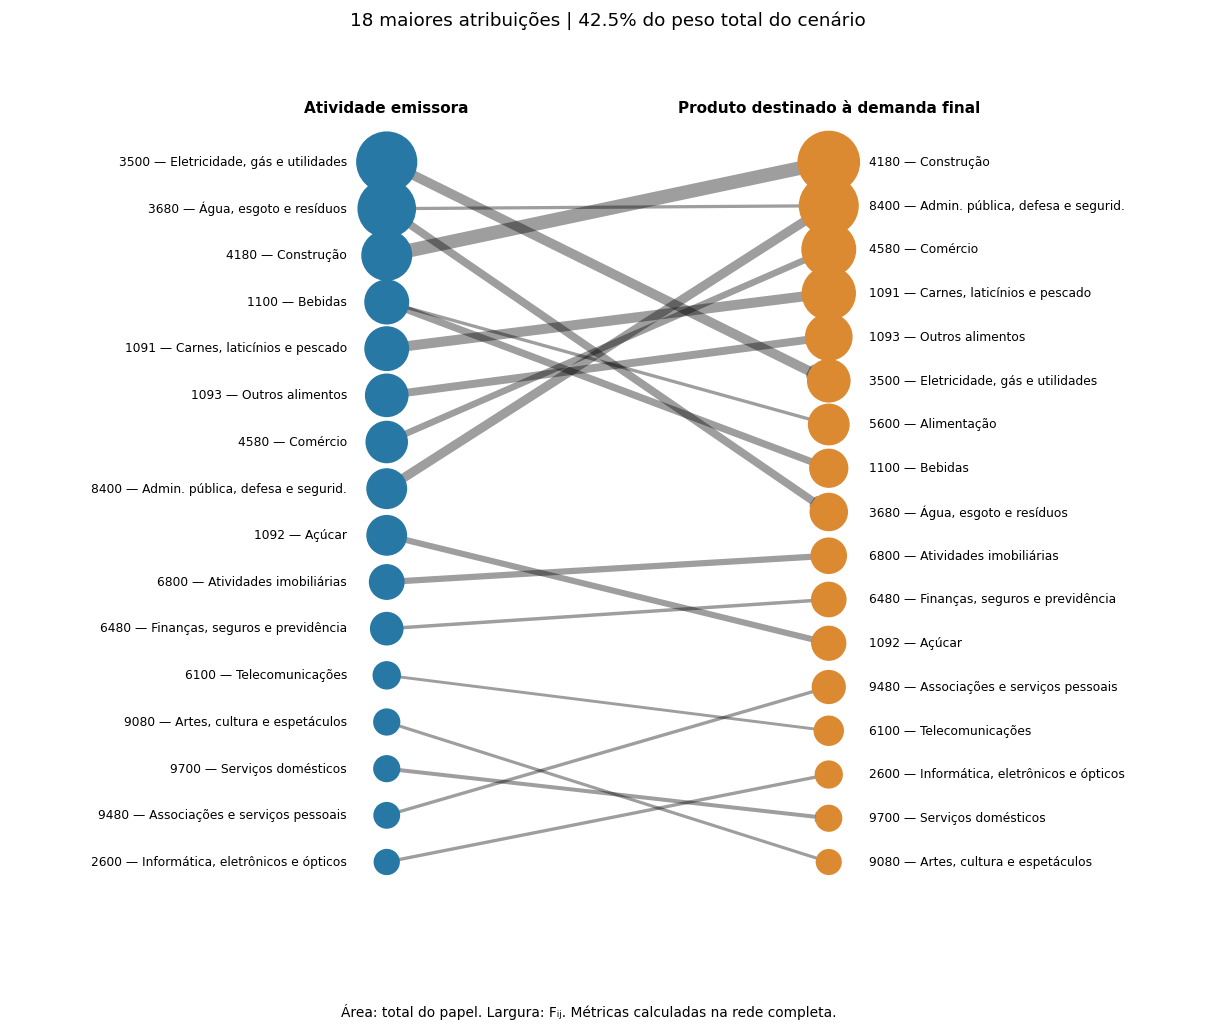

In [7]:
selecionadas=arestas.head(18)
H=G.edge_subgraph([(('emissor',a.emissor),('produto',a.produto)) for a in selecionadas.itertuples()]).copy()
cobertura=selecionadas.peso_gg.sum()/E
pos={}
for papel,xx,total in [('emissor',0,c),('produto',1,u)]:
    nodes=sorted([n for n in H if n[0]==papel],key=lambda n:(-total[n[1]],n[1]))
    pos.update({n:(xx,yy) for n,yy in zip(nodes,np.linspace(1,0,len(nodes)))})
max_total=max(c.max(),u.max())
fig,ax=plt.subplots(figsize=(14,10))
nx.draw_networkx_nodes(H,pos,node_size=[H.nodes[n]['total_gg']/max_total*1600 for n in H],node_color=['#2878a5' if n[0]=='emissor' else '#dc8a32' for n in H],ax=ax)
nx.draw_networkx_edges(H,pos,width=[H.edges[e]['weight']/selecionadas.peso_gg.max()*9 for e in H.edges],alpha=.38,arrows=True,arrowsize=12,node_size=0,ax=ax)
for n,(xx,yy) in pos.items():
    ax.text(xx+(-.09 if xx==0 else .09),yy,f'{n[1]} — {nomes[n[1]]}',ha='right' if xx==0 else 'left',va='center',fontsize=8)
ax.text(0,1.07,'Atividade emissora',ha='center',weight='bold')
ax.text(1,1.07,'Produto destinado à demanda final',ha='center',weight='bold')
ax.set_title(f'18 maiores atribuições | {cobertura:.1%} do peso total do cenário',pad=30)
ax.set(xlim=(-.85,1.85),ylim=(-.08,1.13)); ax.axis('off')
fig.text(.5,.02,'Área: total do papel. Largura: Fᵢⱼ. Métricas calculadas na rede completa.',ha='center',fontsize=9)
fig.savefig(saida/'rede_maiores_ligacoes.png',bbox_inches='tight'); plt.show()
print(f'Peso omitido: {1-cobertura:.1%}. Ligações entre a mesma atividade: {selecionadas.mesma_atividade.sum()} de 18.')

### 7.1. Relações entre atividades distintas

Figura complementar: 18 maiores ligações com i ≠ j. Retirar a própria atividade **somente da seleção gráfica** torna visíveis relações que compõem os saldos. Informamos cobertura do total e do peso externo. As métricas principais continuam calculadas em F completa.

Cobertura do peso entre atividades distintas: 19.0%. Contas e métricas mantêm a diagonal.


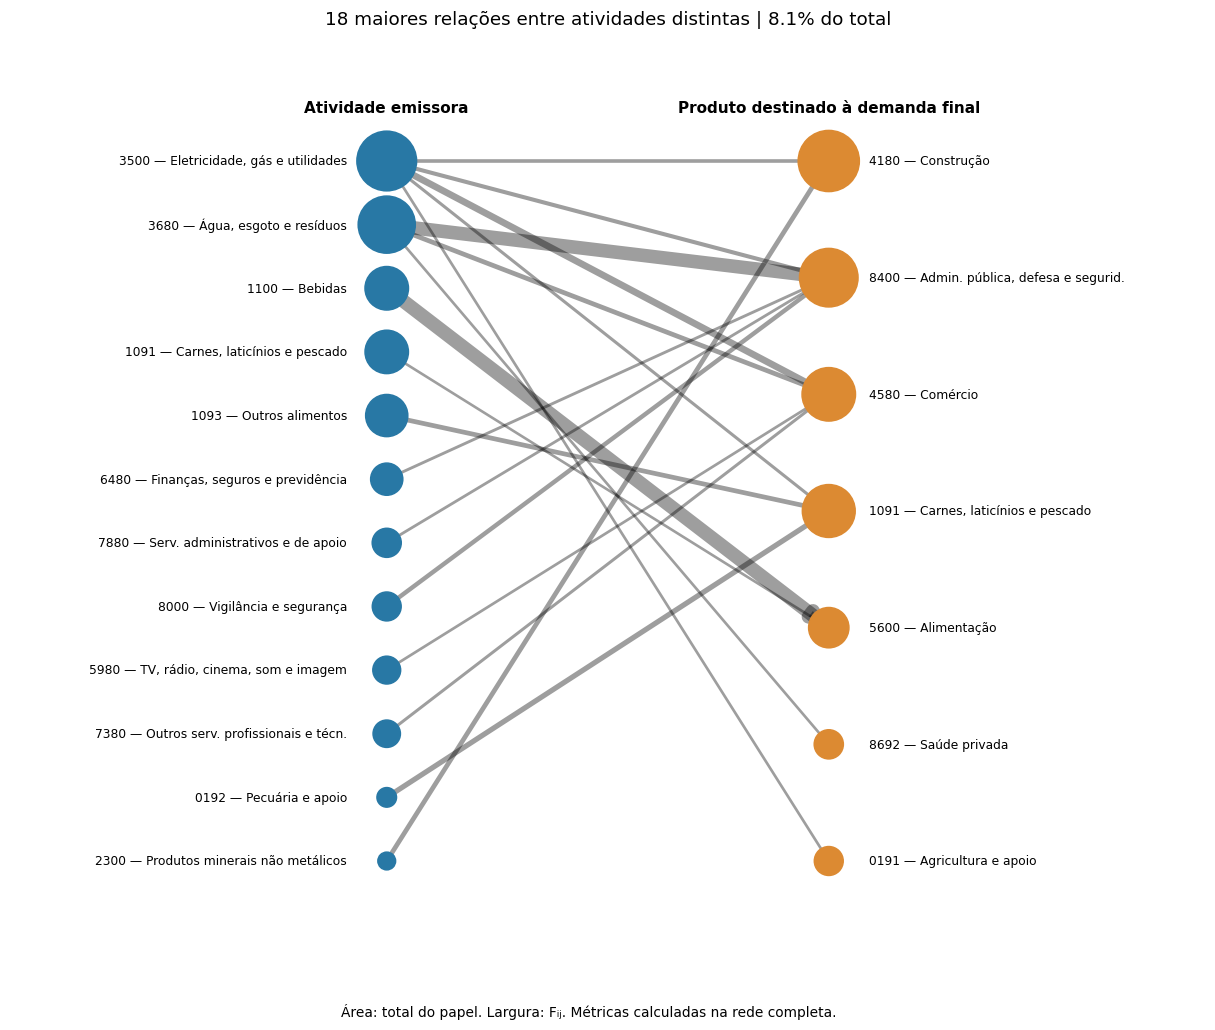

In [8]:
selecionadas_ext=arestas.loc[~arestas.mesma_atividade].head(18)
H=G.edge_subgraph([(('emissor',a.emissor),('produto',a.produto)) for a in selecionadas_ext.itertuples()]).copy()
cobertura_ext=selecionadas_ext.peso_gg.sum()/E
cobertura_peso_externo=selecionadas_ext.peso_gg.sum()/(E-diagonal.sum())
pos={}
for papel,xx,total in [('emissor',0,c),('produto',1,u)]:
    nodes=sorted([n for n in H if n[0]==papel],key=lambda n:(-total[n[1]],n[1]))
    pos.update({n:(xx,yy) for n,yy in zip(nodes,np.linspace(1,0,len(nodes)))})
max_total=max(c.max(),u.max())
fig,ax=plt.subplots(figsize=(14,10))
nx.draw_networkx_nodes(H,pos,node_size=[H.nodes[n]['total_gg']/max_total*1600 for n in H],node_color=['#2878a5' if n[0]=='emissor' else '#dc8a32' for n in H],ax=ax)
nx.draw_networkx_edges(H,pos,width=[H.edges[e]['weight']/selecionadas_ext.peso_gg.max()*9 for e in H.edges],alpha=.38,arrows=True,arrowsize=12,node_size=0,ax=ax)
for n,(xx,yy) in pos.items():
    ax.text(xx+(-.09 if xx==0 else .09),yy,f'{n[1]} — {nomes[n[1]]}',ha='right' if xx==0 else 'left',va='center',fontsize=8)
ax.text(0,1.07,'Atividade emissora',ha='center',weight='bold')
ax.text(1,1.07,'Produto destinado à demanda final',ha='center',weight='bold')
ax.set_title(f'18 maiores relações entre atividades distintas | {cobertura_ext:.1%} do total',pad=30)
ax.set(xlim=(-.85,1.85),ylim=(-.08,1.13)); ax.axis('off')
fig.text(.5,.02,'Área: total do papel. Largura: Fᵢⱼ. Métricas calculadas na rede completa.',ha='center',fontsize=9)
fig.savefig(saida/'rede_entre_atividades.png',bbox_inches='tight'); plt.show()
print(f'Cobertura do peso entre atividades distintas: {cobertura_peso_externo:.1%}. Contas e métricas mantêm a diagonal.')

## 8. Saldos, composição e diversidade: figuras para interpretar

O grafo mostra relações dominantes, mas sobreposição não mede diversidade. O primeiro painel compara saldos. O mapa mantém as 67 origens dos 12 produtos com maiores saldos absolutos: cada coluna soma 100%, sem renormalizar a seleção. A dispersão distingue volume e diversidade. Os rótulos numéricos são códigos IBGE, identificados na tabela setorial.

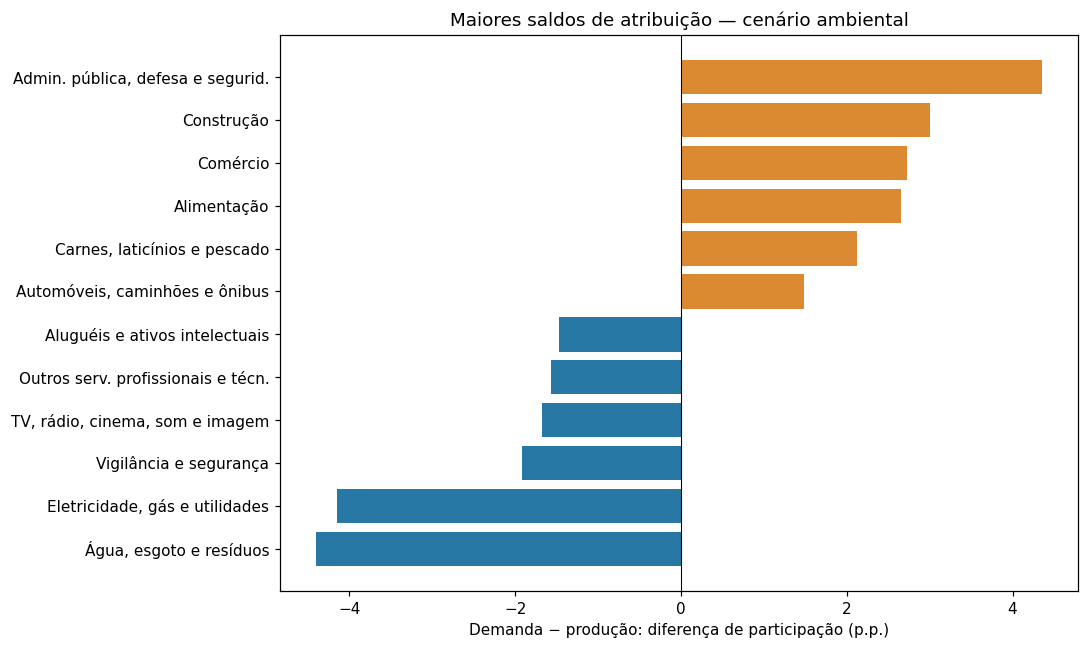

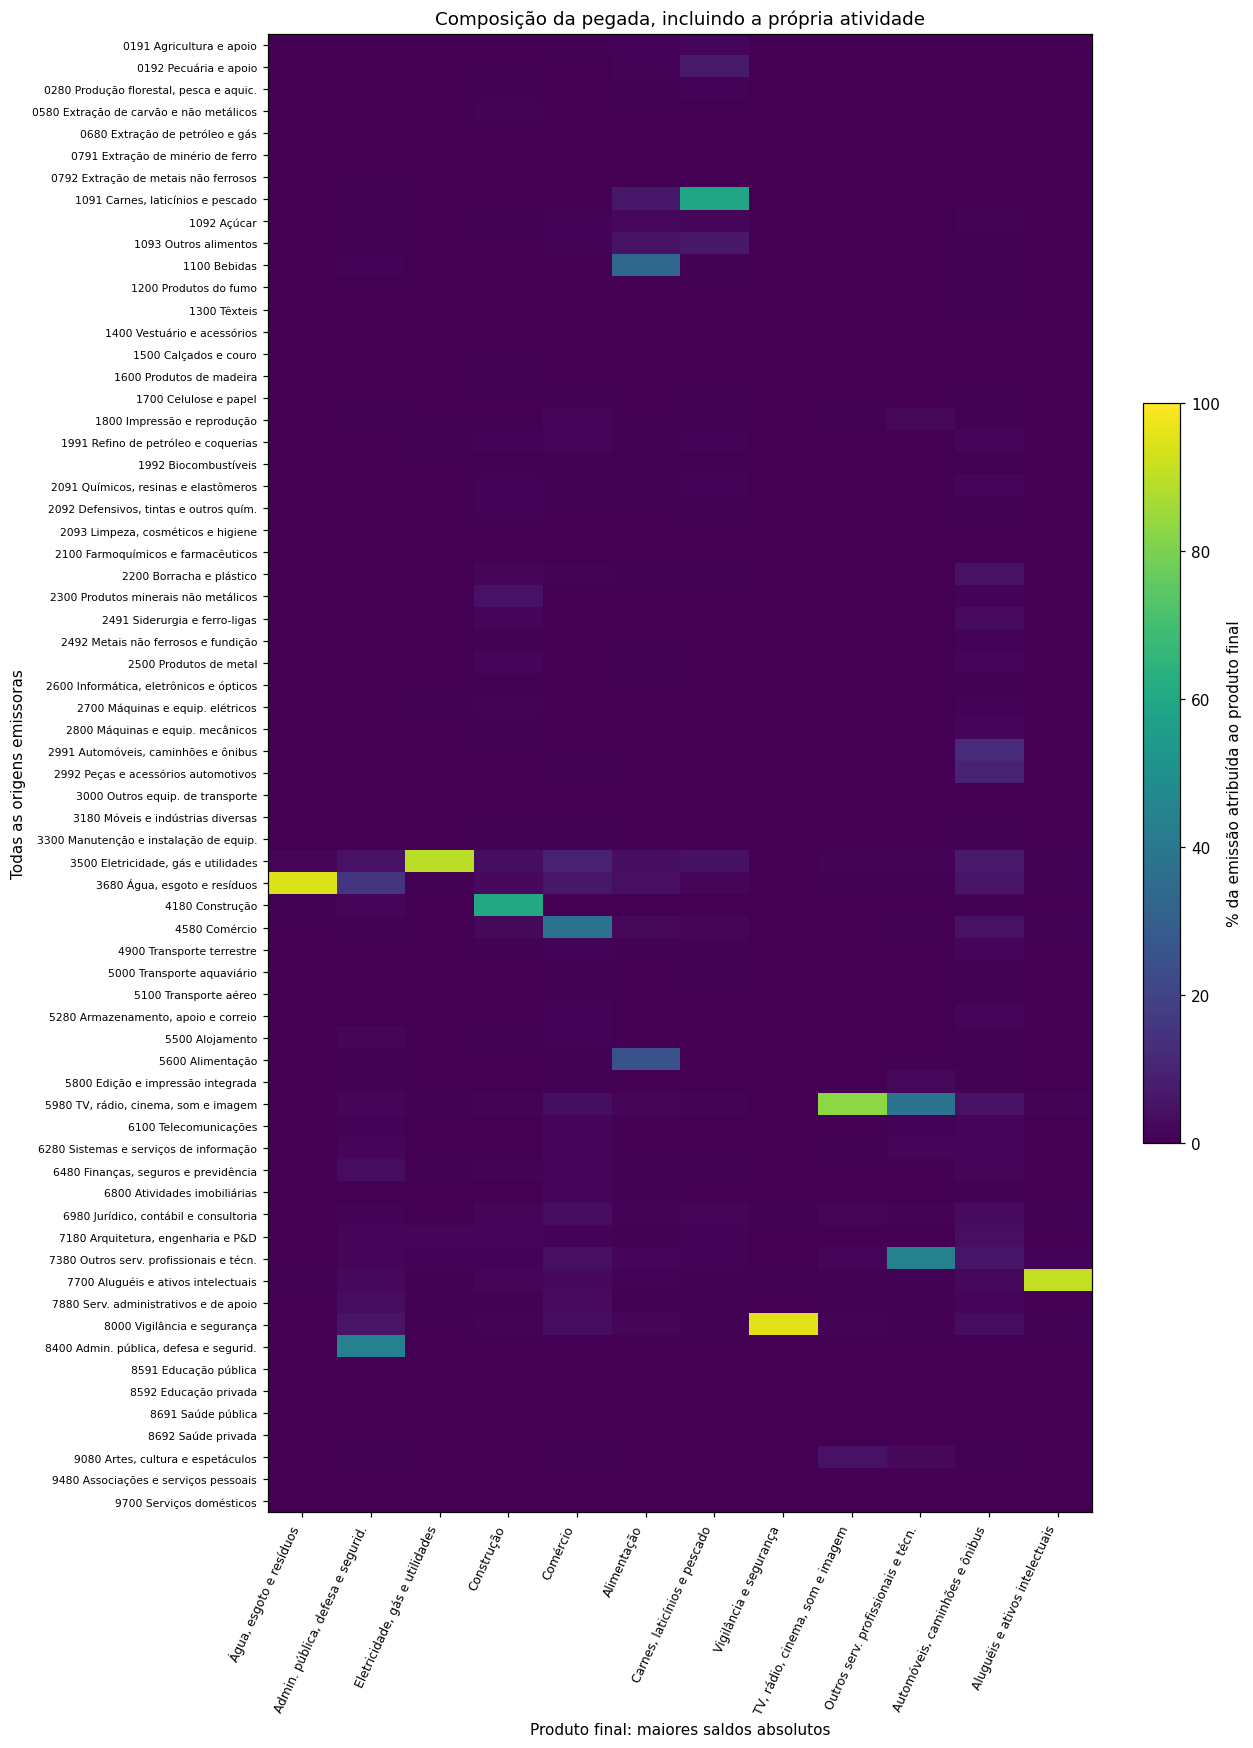

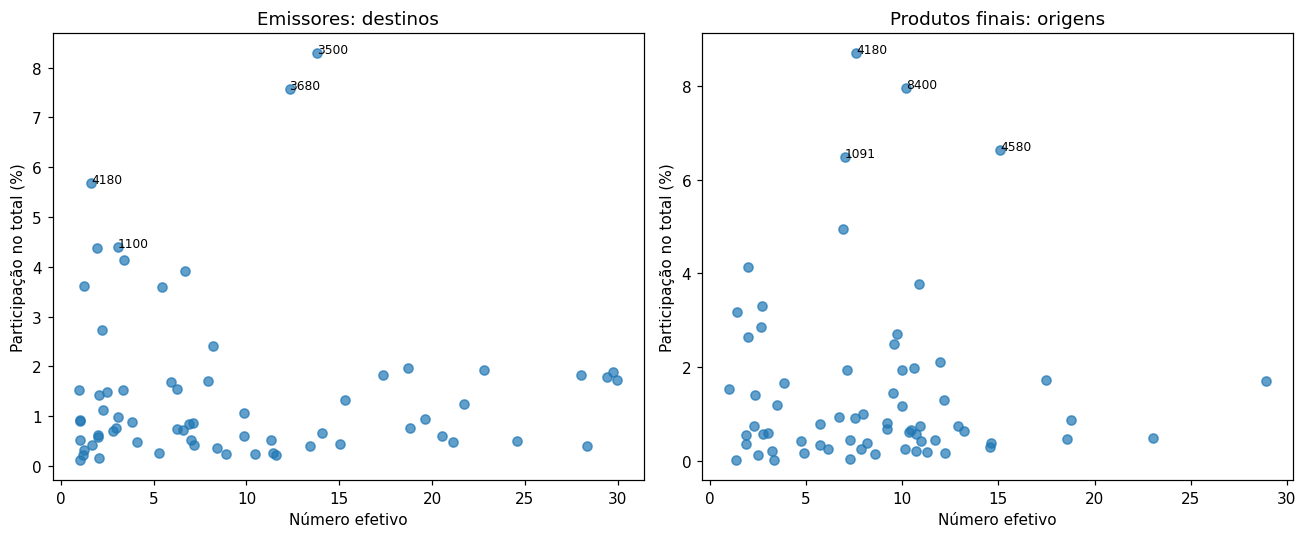

In [9]:
fig,ax=plt.subplots(figsize=(10,6))
valores=metricas.loc[ordem,'delta_pp'].sort_values()
ax.barh([nomes[i] for i in valores.index],valores,color=['#2878a5' if v<0 else '#dc8a32' for v in valores])
ax.axvline(0,color='black',lw=.7)
ax.set(xlabel='Demanda − produção: diferença de participação (p.p.)',title='Maiores saldos de atribuição — cenário ambiental')
fig.tight_layout(); fig.savefig(saida/'saldos_atribuicao.png',bbox_inches='tight'); plt.show()
fig,ax=plt.subplots(figsize=(12,16))
im=ax.imshow(100*r.loc[:,ordem].to_numpy(),aspect='auto',vmin=0,vmax=100,cmap='viridis')
ax.set_yticks(range(len(nomes)),[f'{i} {nomes[i]}' for i in F.index],fontsize=7)
ax.set_xticks(range(len(ordem)),[nomes[i] for i in ordem],rotation=65,ha='right',fontsize=8)
ax.set(xlabel='Produto final: maiores saldos absolutos',ylabel='Todas as origens emissoras',title='Composição da pegada, incluindo a própria atividade')
fig.colorbar(im,ax=ax,label='% da emissão atribuída ao produto final',shrink=.5)
fig.tight_layout(); fig.savefig(saida/'composicao_origens.png',bbox_inches='tight'); plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,col,vol,titulo in [(axes[0],'destinos_efetivos','c_gg','Emissores: destinos'),(axes[1],'origens_efetivas','u_gg','Produtos finais: origens')]:
    ax.scatter(metricas[col],100*metricas[vol]/E,alpha=.7)
    for i in metricas[vol].nlargest(4).index:
        ax.annotate(str(i),(metricas.loc[i,col],100*metricas.loc[i,vol]/E),fontsize=8)
    ax.set(xlabel='Número efetivo',ylabel='Participação no total (%)',title=titulo)
fig.tight_layout(); fig.savefig(saida/'volume_diversidade.png',bbox_inches='tight'); plt.show()

## 9. Relações que compõem os maiores saldos
As listas abaixo mostram cinco relações por direção para os três maiores saldos absolutos. São decomposições parciais; o saldo exato usa todas as ligações. Não interpretar o saldo como emissão evitável.

In [10]:
for i in ordem[:3]:
    print(f'{i} — {nomes[i]} | saldo {metricas.loc[i,"delta_pp"]:+.3f} p.p.')
    entrada=F[i].drop(i).nlargest(5)
    externa=F.loc[i].drop(i).nlargest(5)
    display(pd.DataFrame({'origem_emissora':nomes.reindex(entrada.index),'F_gg':entrada,'pct_pegada':100*entrada/u[i]}))
    display(pd.DataFrame({'destino_final':nomes.reindex(externa.index),'F_gg':externa,'pct_emissao':100*externa/c[i] if c[i]>0 else np.nan}))
print(f'Parcela atribuída à própria atividade: {diagonal.sum()/E:.1%}; entre atividades distintas: {1-diagonal.sum()/E:.1%}.')

3680 — Água, esgoto e resíduos | saldo -4.397 p.p.
8400 — Admin. pública, defesa e segurid. | saldo +4.352 p.p.
3500 — Eletricidade, gás e utilidades | saldo -4.153 p.p.
Parcela atribuída à própria atividade: 57.5%; entre atividades distintas: 42.5%.


,origem_emissora,F_gg,pct_pegada
atividade,,,
3500,"Eletricidade, gás e utilidades",362.583336,1.668065
4180,Construção,108.770202,0.500397
7700,Aluguéis e ativos intelectuais,98.761154,0.454351
8000,Vigilância e segurança,72.486233,0.333473
7180,"Arquitetura, engenharia e P&D",49.847885,0.229325


,destino_final,F_gg,pct_emissao
atividade,,,
8400,"Admin. pública, defesa e segurid.",8501.064382,16.410613
4580,Comércio,2963.770189,5.721317
8692,Saúde privada,1672.361392,3.228358
8691,Saúde pública,1620.980869,3.129172
4180,Construção,1591.975872,3.073180


,origem_emissora,F_gg,pct_pegada
atividade,,,
3680,"Água, esgoto e resíduos",8501.064382,15.618487
8000,Vigilância e segurança,2764.278887,5.078641
3500,"Eletricidade, gás e utilidades",2556.047657,4.696070
6480,"Finanças, seguros e previdência",1810.777891,3.326832
7880,Serv. administrativos e de apoio,1762.503462,3.238140


,destino_final,F_gg,pct_emissao
atividade,,,
4580,Comércio,110.363879,0.447312
4180,Construção,47.005956,0.190518
6480,"Finanças, seguros e previdência",44.570910,0.180649
1093,Outros alimentos,38.700831,0.156857
2991,"Automóveis, caminhões e ônibus",36.809525,0.149191


,origem_emissora,F_gg,pct_pegada
atividade,,,
7180,"Arquitetura, engenharia e P&D",346.859463,1.228817
7380,Outros serv. profissionais e técn.,228.710801,0.810252
5980,"TV, rádio, cinema, som e imagem",202.783428,0.718399
2700,Máquinas e equip. elétricos,172.945352,0.612692
3680,"Água, esgoto e resíduos",141.041541,0.499667


,destino_final,F_gg,pct_emissao
atividade,,,
4580,Comércio,4223.992882,7.460163
8400,"Admin. pública, defesa e segurid.",2556.047657,4.514338
4180,Construção,2262.950752,3.996688
1091,"Carnes, laticínios e pescado",1930.331826,3.409236
0191,Agricultura e apoio,1693.306006,2.990616


## 10. Sensibilidade à diagonal

Retirar a própria atividade muda a pergunta para a diversidade das relações externas. Não é correção de F. Perfis externos nulos ficam indefinidos. Mantemos os totais físicos originais.

In [11]:
F_externa=F.copy()
F_externa=F_externa.mask(np.eye(len(F),dtype=bool),0)
p_ext=F_externa.div(F_externa.sum(axis=1).replace(0,np.nan),axis=0)
r_ext=F_externa.div(F_externa.sum(axis=0).replace(0,np.nan),axis=1)
metricas['destinos_efetivos_externos']=np.exp(-(p_ext*np.log(p_ext.where(p_ext>0))).sum(axis=1,min_count=1))
metricas['origens_efetivas_externas']=np.exp(-(r_ext*np.log(r_ext.where(r_ext>0))).sum(axis=0,min_count=1))
display(metricas.loc[ordem,['nome','destinos_efetivos','destinos_efetivos_externos','origens_efetivas','origens_efetivas_externas']])

,nome,destinos_efetivos,destinos_efetivos_externos,origens_efetivas,origens_efetivas_externas
3680,"Água, esgoto e resíduos",12.320956,21.140575,1.437483,17.715943
8400,"Admin. pública, defesa e segurid.",1.272332,34.665551,10.230158,18.655646
3500,"Eletricidade, gás e utilidades",13.799307,33.191083,1.993851,31.466964
4180,Construção,1.627620,18.440719,7.604814,31.000009
4580,Comércio,6.688993,32.998950,15.095804,27.127876
5600,Alimentação,2.288320,12.785636,10.881414,11.409750
1091,"Carnes, laticínios e pescado",1.926635,9.283842,7.044336,22.302664
8000,Vigilância e segurança,22.822400,22.186252,1.396605,25.119051
5980,"TV, rádio, cinema, som e imagem",29.452364,28.659498,2.542006,17.049571
7380,Outros serv. profissionais e técn.,29.968124,29.003096,4.893230,4.989453


In [12]:
print(f'Leitura das figuras: as 18 maiores ligações completas retêm {cobertura:.1%} do cenário; {selecionadas.mesma_atividade.sum()} são atribuições à própria atividade.')
print(f'As 18 ligações externas retêm {cobertura_peso_externo:.1%} do peso entre atividades distintas.')
for sentido,col in [('destinos dos emissores','destinos_efetivos'),('origens dos produtos','origens_efetivas')]:
    valores=metricas[col].dropna()
    print(f'Diversidade efetiva de {sentido}: mediana {valores.median():.2f}; intervalo {valores.min():.2f}–{valores.max():.2f}; {len(valores)} perfis definidos.')
print('Esses números descrevem o cenário e não resolvem as limitações dos coeficientes ambientais.')

Leitura das figuras: as 18 maiores ligações completas retêm 42.5% do cenário; 16 são atribuições à própria atividade.
As 18 ligações externas retêm 19.0% do peso entre atividades distintas.
Diversidade efetiva de destinos dos emissores: mediana 6.91; intervalo 1.00–29.97; 67 perfis definidos.
Diversidade efetiva de origens dos produtos: mediana 8.16; intervalo 1.00–28.93; 67 perfis definidos.
Esses números descrevem o cenário e não resolvem as limitações dos coeficientes ambientais.


## 11. O que pode ser concluído com cada representação

- **Grafo selecionado:** identifica grandes pares origem/destino, dentro da cobertura exibida; ausência no desenho não significa ausência de relação.
- **Saldo e decomposição:** mostram quais relações compõem a diferença entre as duas atribuições. Não identificam efeitos causais.
- **Perfis e diversidade:** distinguem concentração e distribuição, sem confundir essas dimensões com volume.
- **Sankey:** a v4 e `sankeys_mip20_67.ipynb` já representam F entre esses dois papéis. Pode acompanhar o método ou ir ao anexo; não é evidência independente.

Para o texto principal, priorizar saldos, composição e diversidade. O grafo só deve permanecer se facilitar a explicação de relações concretas. Não inferir essencialidade, substituição, prioridade ótima de mitigação ou etapas produtivas a partir de caminhos em F. Validar ou substituir os coeficientes antes de afirmar resultados ambientais observados. Aplicar o método a SC/2018 exige harmonização própria e respeito à fronteira estadual.

## Anexo A. Rede completa

Todos os nós e ligações positivas, sem seleção. A ordem setorial é igual nos dois lados. Área dos nós e largura das arestas são lineares nos volumes. Sobreposição limita a leitura: densidade de linhas não demonstra intensidade de dependência. A tabela de arestas é a versão auditável.

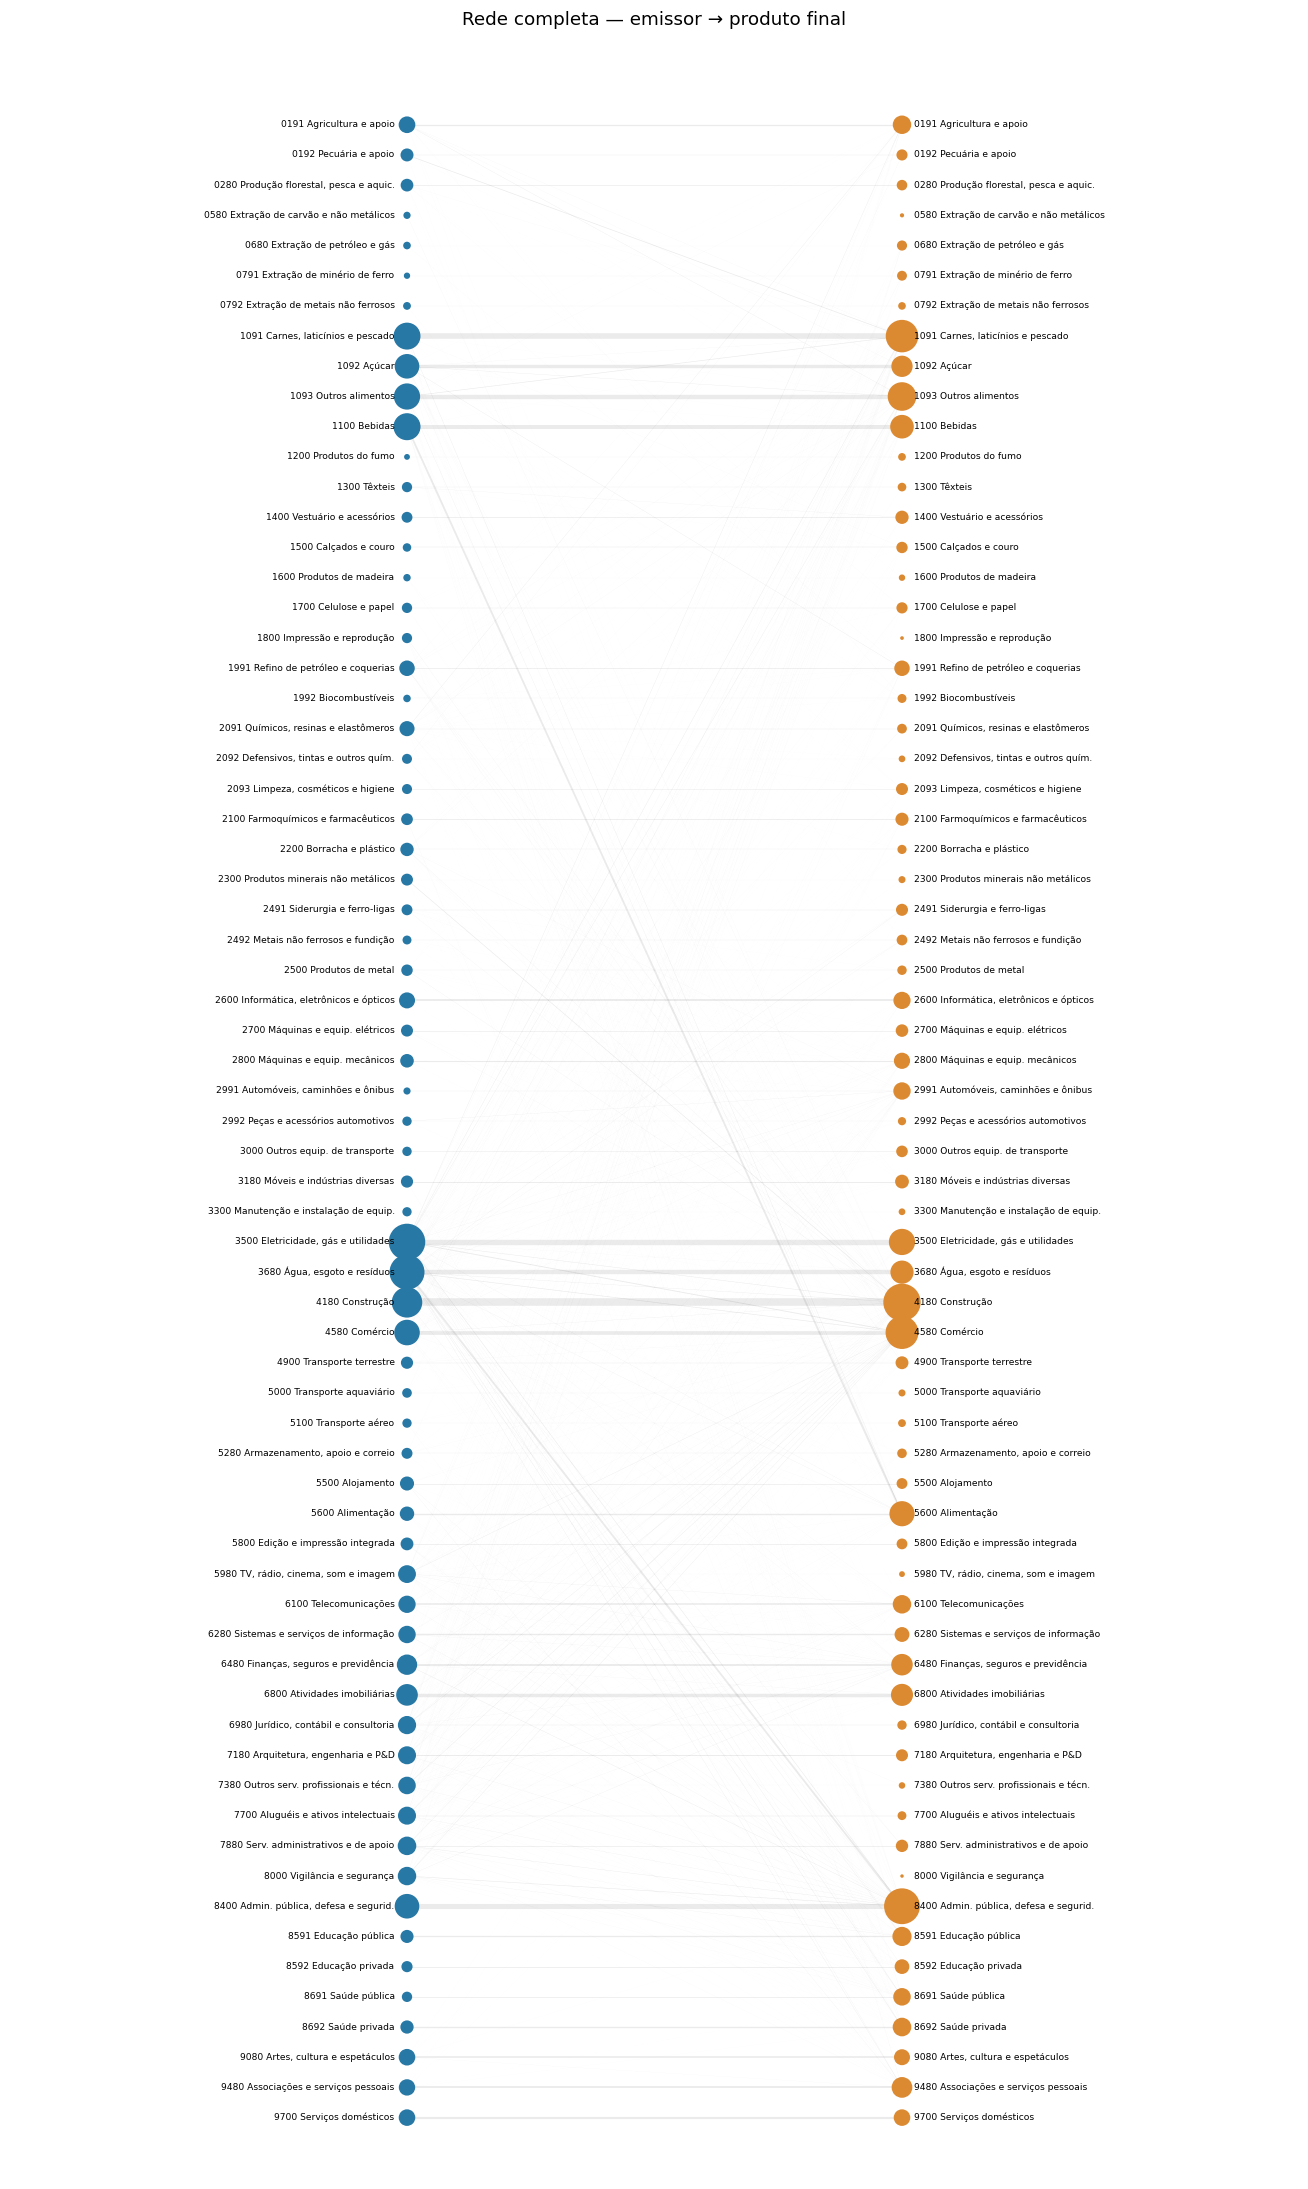

In [13]:
pos_completa={}
for k,i in enumerate(F.index):
    pos_completa[('emissor',i)]=(0,-k)
    pos_completa[('produto',i)]=(1,-k)
fig,ax=plt.subplots(figsize=(12,20))
nx.draw_networkx_nodes(G,pos_completa,node_size=[G.nodes[n]['total_gg']/max_total*550 for n in G],node_color=['#2878a5' if n[0]=='emissor' else '#dc8a32' for n in G],ax=ax)
nx.draw_networkx_edges(G,pos_completa,arrows=False,alpha=.08,width=[G.edges[e]['weight']/arestas.peso_gg.max()*5 for e in G.edges],ax=ax)
for i in F.index:
    yy=pos_completa[('emissor',i)][1]
    ax.text(-.025,yy,f'{i} {nomes[i]}',ha='right',va='center',fontsize=6)
    ax.text(1.025,yy,f'{i} {nomes[i]}',ha='left',va='center',fontsize=6)
ax.set(xlim=(-.8,1.8),ylim=(-68,3),title='Rede completa — emissor → produto final')
ax.axis('off'); fig.tight_layout()
fig.savefig(saida/'anexo_rede_completa.png',bbox_inches='tight'); plt.show()

## Anexo B. Exportação e rastreabilidade
Matrizes, participações e métricas são do cenário, não dados observados. A lista gráfica e a lista completa de arestas são exportadas separadamente.

In [14]:
for nome,obj in [('F_gg',F),('C_intensidades',C),('participacoes_destinos',p),('participacoes_origens',r),('metricas_setoriais',metricas)]:
    obj.to_csv(saida/f'{nome}.csv',encoding='utf-8-sig')
arestas.to_csv(saida/'arestas_completas.csv',index=False,encoding='utf-8-sig')
selecionadas_ext.to_csv(saida/'arestas_figura_externas.csv',index=False,encoding='utf-8-sig')
selecionadas.to_csv(saida/'arestas_figura.csv',index=False,encoding='utf-8-sig')
registro={'notebook':'rede_bipartida_atribuicao_2015.ipynb','ano':2015,'entradas':['mip_ibge_2015_67','sanguinet_azzoni_2011','sanguinet_azzoni_2018'],'status':'cenário exploratório; ver auditoria','python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'networkx':nx.__version__,'nos':G.number_of_nodes(),'arestas':G.number_of_edges(),'cobertura_grafo_18':float(cobertura),'total_gg':float(E)}
(saida/'proveniencia.json').write_text(json.dumps(registro,ensure_ascii=False,indent=2),encoding='utf-8')
print('Saídas:',saida.resolve())

Saídas: C:\GitHub\Redes-1\outputs\rede_bipartida_atribuicao_2015
